# ボディ検査機 生産実績レポート
---

In [28]:
import sqlite3

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

from IPython.display import Markdown, display

# ================================================
#   Settings
# ================================================
plt.rcParams["font.family"] = "Yu Gothic"

DB_PATH = "body_inspection_machine.db"

START_DATE = "2026-09-01"
END_DATE = "2026-09-30"

display(
    Markdown(
        f"**集計期間：{START_DATE} ～ {END_DATE}**"
    )
)

**集計期間：2026-09-01 ～ 2026-09-30**

### 1. 設備別 生産数
指定期間における各設備の生産数（OK数）を集計する。

In [29]:
sql = """
SELECT
    inspection_machine_no,
    SUM(ok_count) AS production_count
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_production = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

display(
    df_production.rename(
        columns={
            "inspection_machine_no": "設備番号",
            "production_count": "生産数",
        }
    ).style.format(
        {
            "生産数": "{:,}",
        }
    )
)

,設備番号,生産数
0,412,"294,941"
1,413,"270,490"
2,416,"254,573"
3,421,"235,501"
4,428,"305,445"


##### 設備別 生産数グラフ

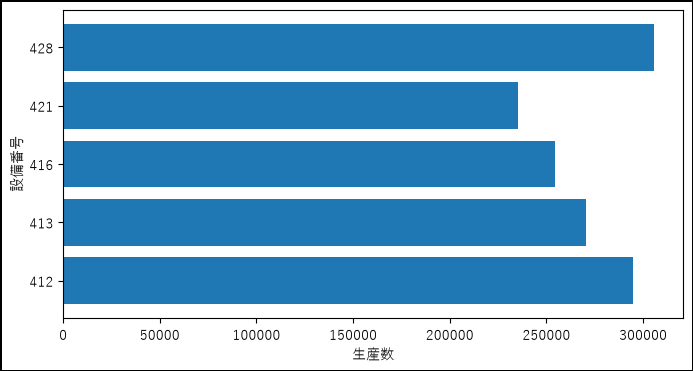

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))

fig.patch.set_edgecolor("black")
fig.patch.set_linewidth(1.0)

ax.barh(
    df_production["inspection_machine_no"].astype(str),
    df_production["production_count"],
)

ax.set_xlabel("生産数")
ax.set_ylabel("設備番号")

plt.show()

---
### 2. 設備別 日別生産数

指定期間における各設備の日別生産数（OK数）の推移を表示する。
生産データが存在しない日付は0として補完する。

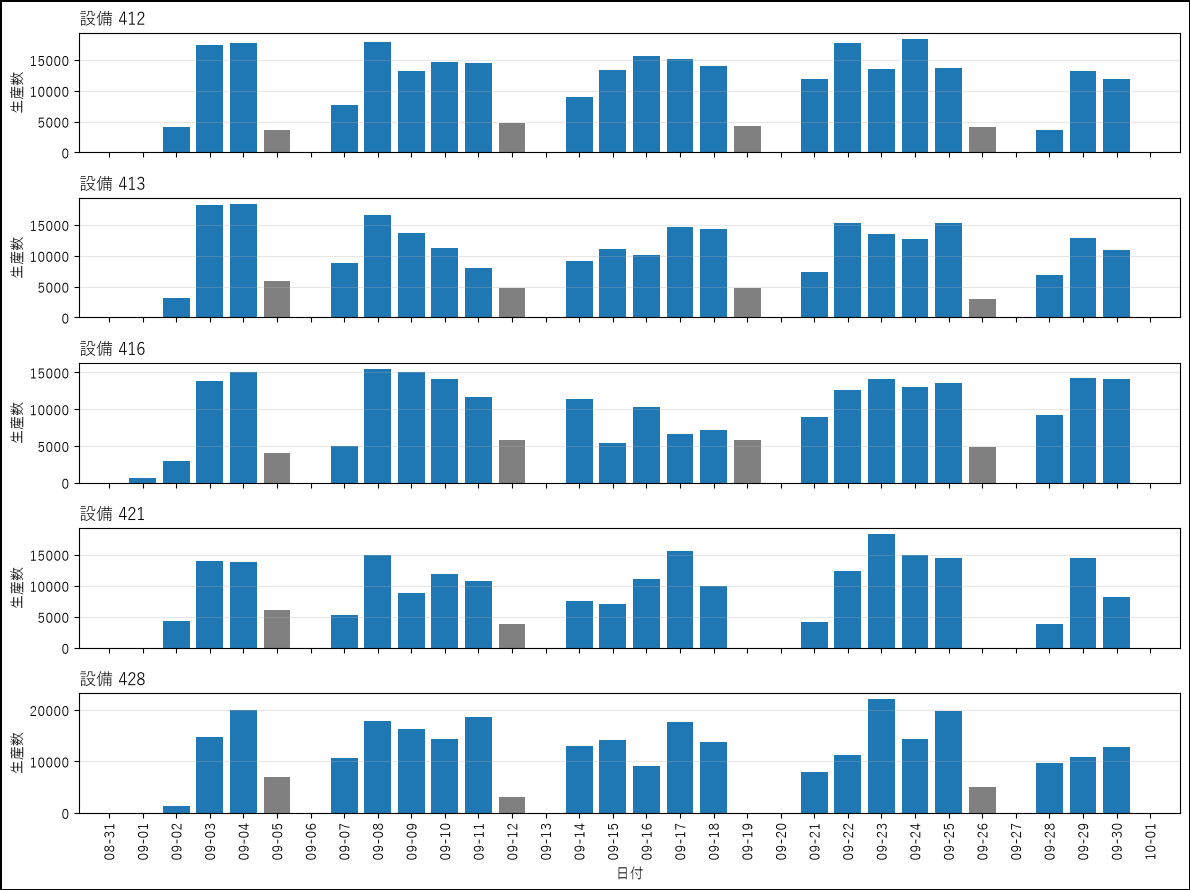

In [31]:
sql = """
SELECT
    record_date,
    inspection_machine_no,
    SUM(ok_count) AS production_count
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY record_date, inspection_machine_no
ORDER BY record_date, inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_daily = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

# 指定期間の全日付を作成
date_range = pd.date_range(
    start=START_DATE,
    end=END_DATE,
    freq="D",
)

# 設備番号を取得
machine_numbers = sorted(df_daily["inspection_machine_no"].unique())

# グラフ作成
fig, axes = plt.subplots(
    len(machine_numbers),
    1,
    figsize=(12, 9),
    sharex=True,
)

fig.patch.set_edgecolor("black")
fig.patch.set_linewidth(1.0)

for ax, machine_no in zip(axes, machine_numbers):
    df_machine = df_daily[
        df_daily["inspection_machine_no"] == machine_no
    ].copy()

    df_machine["record_date"] = pd.to_datetime(
        df_machine["record_date"]
    )

    df_machine = (
        df_machine.set_index("record_date")
        .reindex(date_range, fill_value=0)
    )

    colors = [
        "gray" if date.weekday() >= 5 else "tab:blue"
        for date in df_machine.index
    ]

    ax.bar(
        df_machine.index,
        df_machine["production_count"],
        color=colors,
    )

    ax.set_title(f"設備 {machine_no}", loc="left")
    ax.set_ylabel("生産数")
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel("日付")
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[-1].tick_params(axis="x", labelrotation=90)

fig.tight_layout()

plt.show()

---
### 3. 設備別 NG発生状況

指定期間における各設備のNG発生状況

In [32]:
sql = """
SELECT
    inspection_machine_no,
    SUM(ok_count) AS ok_count,
    SUM(ngcount_total1) AS ngcount_total1
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_summary = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

total_count = (
    df_summary["ok_count"]
    + df_summary["ngcount_total1"]
)

df_summary["ok_ratio"] = (
    df_summary["ok_count"]
    / total_count
)

df_summary["ngcount_ratio"] = (
    df_summary["ngcount_total1"]
    / total_count
)

df_summary = df_summary[
    [
        "inspection_machine_no",
        "ok_count",
        "ok_ratio",
        "ngcount_total1",
        "ngcount_ratio",
    ]
]

display(
    df_summary.style.format(
        {
            "ok_count": "{:,}",
            "ok_ratio": "{:.2%}",
            "ngcount_total1": "{:,}",
            "ngcount_ratio": "{:.2%}",
        }
    )
)

,inspection_machine_no,ok_count,ok_ratio,ngcount_total1,ngcount_ratio
0,412,"294,941",97.89%,"6,348",2.11%
1,413,"270,490",95.32%,"13,271",4.68%
2,416,"254,573",95.16%,"12,953",4.84%
3,421,"235,501",94.16%,"14,593",5.84%
4,428,"305,445",97.54%,"7,713",2.46%


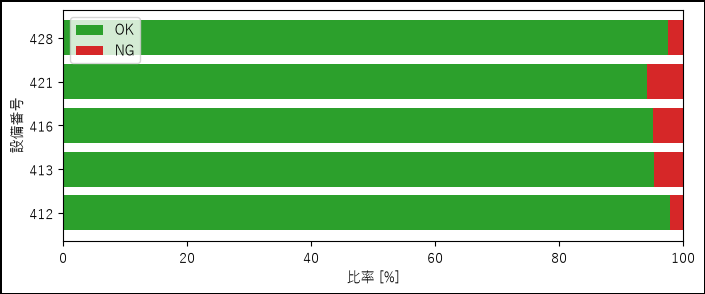

In [33]:
fig, ax = plt.subplots(figsize=(8, 3))

fig.patch.set_edgecolor("black")
fig.patch.set_linewidth(1.0)

machine_numbers = df_summary["inspection_machine_no"].astype(str)

ax.barh(
    machine_numbers,
    df_summary["ok_ratio"] * 100,
    color="tab:green",
    label="OK",
)

ax.barh(
    machine_numbers,
    df_summary["ngcount_ratio"] * 100,
    left=df_summary["ok_ratio"] * 100,
    color="tab:red",
    label="NG",
)

ax.set_xlim(0, 100)
ax.set_xlabel("比率 [%]")
ax.set_ylabel("設備番号")
ax.legend()

plt.show()

In [34]:
sql = """
SELECT name
FROM pragma_table_info('inspection_data')
WHERE name LIKE '%_ngcount1'
"""

with sqlite3.connect(DB_PATH) as conn:
    cursor = conn.execute(sql)
    ng_columns = [row[0] for row in cursor]

# print(ng_columns)

sum_columns = ",\n    ".join(
    f"SUM({column}) AS {column}"
    for column in ng_columns
)

sql = f"""
SELECT
    inspection_machine_no,
    {sum_columns}
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_ngcount = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

display(
    df_ngcount.style.set_table_styles(
        [
            {
                "selector": "th",
                "props": [
                    ("max-width", "100px"),
                    ("white-space", "normal"),
                    ("word-wrap", "break-word"),
                    ("text-align", "center"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("min-width", "80px"),
                    ("max-width", "100px"),
                    ("text-align", "right"),
                ],
            },
        ]
    )
)

,inspection_machine_no,inner_d_ngcount1,phi071_ngcount1,total_length_ngcount1,taper_thickness_ngcount1,level_gap_ngcount1,bottom_ngcount1,thickness_ngcount1,side_visual1_ngcount1,side_visual2_ngcount1,phi2435_depth_ngcount1,phi14_depth_ngcount1
0,412,918,903,1,454,0,53,5,3805,0,28,178
1,413,399,4004,4,2443,0,47,786,3062,0,1228,1279
2,416,6389,2290,6,835,0,0,177,4377,0,4,0
3,421,2592,5200,3905,0,116,144,1289,1293,5,24,1
4,428,574,817,1504,41,0,561,351,3838,35,0,0


---
### 4. 設備別 アラーム発生状況

指定期間における各設備のアラーム発生状況

In [35]:
sql = """
SELECT name
FROM pragma_table_info('inspection_data')
WHERE name LIKE '%_alarm_count'
"""

with sqlite3.connect(DB_PATH) as conn:
    cursor = conn.execute(sql)
    alarm_columns = [row[0] for row in cursor]

alarm_sum = "\n        + ".join(alarm_columns)

sql = f"""
SELECT
    inspection_machine_no,
    SUM(
        {alarm_sum}
    ) AS alarm_count_total
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_alarm = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

display(df_alarm)

,inspection_machine_no,alarm_count_total
0,412,956
1,413,976
2,416,1565
3,421,619
4,428,645


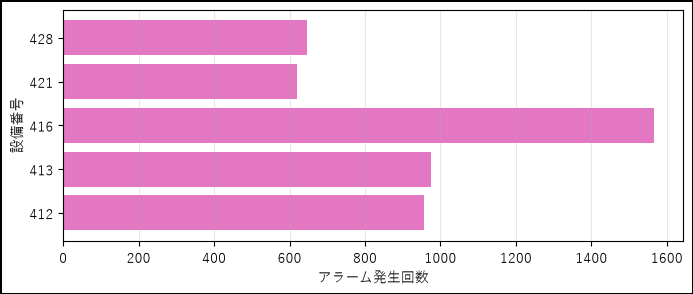

In [36]:
fig, ax = plt.subplots(figsize=(8, 3))

fig.patch.set_edgecolor("black")
fig.patch.set_linewidth(1.0)

ax.barh(
    df_alarm["inspection_machine_no"].astype(str),
    df_alarm["alarm_count_total"],
    color="tab:pink",
)

ax.set_xlabel("アラーム発生回数")
ax.set_ylabel("設備番号")
ax.grid(axis="x", alpha=0.3)

plt.show()

In [37]:
# アラーム種類別に集計
sum_columns = ",\n    ".join(
    f"SUM({column}) AS {column}"
    for column in alarm_columns
)

sql = f"""
SELECT
    inspection_machine_no,
    {sum_columns}
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_alarm_detail = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

display(df_alarm_detail)

,inspection_machine_no,st1_alarm_count,st2_alarm_count,st3_alarm_count,st4_alarm_count,st5_alarm_count,st6_alarm_count,st7_alarm_count,st8_alarm_count,others_alarm_count
0,412,19,107,1,0,8,282,1,15,523
1,413,14,28,0,0,1,43,1,141,748
2,416,392,547,0,0,7,2,20,19,578
3,421,17,175,3,0,0,3,0,0,421
4,428,34,148,10,1,24,6,30,0,392
